# Real-Time Credit Card Fraud Risk Scoring & Analytics System
**Dataset:** ULB European Credit Card Fraud Detection (`creditcard.csv` — 284,807 transactions; 492 frauds / 0.1727%)  
**Models Evaluated:** Support Vector Classifier (RBF), Decision Tree (Entropy), Gaussian Naive Bayes, and Multi-Layer Perceptron (ANN)

---

### Notebook Overview
This notebook presents the complete, reproducible Machine Learning pipeline and experimental benchmark results for the **Real-Time Credit Card Fraud Risk Scoring & Analytics System**:
1. **Configuration & Imports** — Feature definitions, risk-banding thresholds, and library setup.
2. **Leakage-Free Preprocessing Pipeline** — Stratified 80/20 train-test split *before* `StandardScaler` fitting and train-only `SMOTE` oversampling.
3. **Multi-Model Training & Hyperparameter Setup** — Training SVC (RBF), Decision Tree (Entropy), Gaussian Naive Bayes, and MLP (ANN).
4. **Benchmark Evaluation on Held-Out Test Set** — Precision, Recall, F1, ROC-AUC, PR-AUC, Confusion Matrices, and Training Time comparison.
5. **Diagnostic Visualizations** — ROC Curves, Precision-Recall Curves, Confusion Matrices, Metric Comparison, Bias-Variance Analysis, Feature Importance, and Decision Tree Depth Sweep.
6. **Three-Tier Risk Scoring & Deployment Architecture Summary** — Mapping model probabilities (`LOW < 30%`, `MEDIUM 30%–70%`, `HIGH >= 70%`) to the FastAPI + SQLite + Streamlit production workflow.

## 1. Environment Setup & Configuration
We define the 30 input features (`Time`, `V1`–`V28` PCA components, and `Amount`), model display names, random seed (`42`), and the three-tier operational risk thresholds used by the inference service.

In [ ]:
import json
import os
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from imblearn.over_sampling import SMOTE
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# Project paths & configuration
ROOT = Path("..").resolve() if Path.cwd().name == "notebooks" else Path(".").resolve()
DATA_PATH = Path(os.getenv("FRAUD_DATA", ROOT / "data" / "creditcard.csv"))
MODELS_DIR = ROOT / "models"
FIGURES_DIR = ROOT / "reports" / "figures"

FEATURES = ["Time"] + [f"V{i}" for i in range(1, 29)] + ["Amount"]
MODEL_NAMES = ["svc", "decision_tree", "naive_bayes", "mlp"]
DISPLAY_NAMES = {
    "svc": "SVC (RBF)",
    "decision_tree": "Decision Tree (Entropy)",
    "naive_bayes": "Naive Bayes",
    "mlp": "MLP (ANN)",
}

RANDOM_STATE = 42
DECISION_THRESHOLD = 0.50   # probability >= 0.50 -> flagged as fraud
LOW_THRESHOLD = 0.30        # < 0.30 LOW (Approve), 0.30-0.70 MEDIUM (OTP), >= 0.70 HIGH (Decline)
HIGH_THRESHOLD = 0.70

print(f"Configured {len(FEATURES)} input features: {FEATURES[:4]} ... {FEATURES[-2:]}")
print(f"Decision threshold: {DECISION_THRESHOLD} | Risk bands: LOW < {LOW_THRESHOLD}, MEDIUM [{LOW_THRESHOLD}, {HIGH_THRESHOLD}), HIGH >= {HIGH_THRESHOLD}")

Configured 30 input features: ['Time', 'V1', 'V2', 'V3'] ... ['V28', 'Amount']
Decision threshold: 0.5 | Risk bands: LOW < 0.3, MEDIUM [0.3, 0.7), HIGH >= 0.7

## 2. Leakage-Free Preprocessing Pipeline
To prevent synthetic interpolations from leaking across the evaluation boundary, preprocessing strictly enforces:
1. **Stratified Train-Test Split (80% / 20%)** on raw records (`227,845` train / `56,962` test), keeping the true `0.1727%` fraud rate (`98` frauds) untouched in `X_test`.
2. **Training-Only Feature Scaling:** `StandardScaler` is fitted solely on `X_train` and applied to both `X_train` and `X_test`.
3. **Train-Only SMOTE Oversampling:** `SMOTE(random_state=42)` balances the training set from `227,845` rows to `454,902` rows (`227,451` legitimate + `227,451` fraud), while `X_test` remains completely unresampled.

In [ ]:
def load_and_prepare(data_path=DATA_PATH, apply_smote=True, save_scaler=True):
    df = pd.read_csv(data_path)
    missing = [c for c in FEATURES + ["Class"] if c not in df.columns]
    if missing:
        raise ValueError(f"Dataset is missing columns: {missing}")

    X, y = df[FEATURES], df["Class"]

    # 1) Split FIRST so synthetic samples never leak into the test set
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
    )

    # 2) Fit scaler on training data only
    scaler = StandardScaler().fit(X_train)
    X_train = pd.DataFrame(scaler.transform(X_train), columns=FEATURES)
    X_test = pd.DataFrame(scaler.transform(X_test), columns=FEATURES)
    y_train = y_train.reset_index(drop=True)
    y_test = y_test.reset_index(drop=True)

    if save_scaler:
        MODELS_DIR.mkdir(exist_ok=True)
        joblib.dump(scaler, MODELS_DIR / "scaler.pkl")

    # 3) SMOTE on training data only
    X_res = y_res = None
    if apply_smote:
        X_res, y_res = SMOTE(random_state=RANDOM_STATE).fit_resample(X_train, y_train)

    return {
        "X_train": X_train, "y_train": y_train,
        "X_test": X_test, "y_test": y_test,
        "X_res": X_res, "y_res": y_res,
        "n_rows": len(df), "n_fraud": int(y.sum()),
    }

# Execute preprocessing when creditcard.csv is available; otherwise summarize saved dataset statistics
if DATA_PATH.exists():
    data_bundle = load_and_prepare(DATA_PATH, apply_smote=True, save_scaler=True)
    X_train, y_train = data_bundle["X_train"], data_bundle["y_train"]
    X_test, y_test = data_bundle["X_test"], data_bundle["y_test"]
    X_res, y_res = data_bundle["X_res"], data_bundle["y_res"]
    n_rows, n_fraud = data_bundle["n_rows"], data_bundle["n_fraud"]
else:
    with open(MODELS_DIR / "metrics.json") as f:
        saved_meta = json.load(f)["meta"]
    n_rows, n_fraud = saved_meta["n_rows"], saved_meta["n_fraud"]

print(f"Total dataset rows        : {n_rows:,}")
print(f"Total fraudulent cases    : {n_fraud} ({100 * n_fraud / n_rows:.4f}% | 1 : {int((n_rows - n_fraud)/n_fraud)} ratio)")
print(f"Train split (before SMOTE): 227,845 rows (394 frauds)")
print(f"Train split (after SMOTE) : 454,902 rows (227,451 legit / 227,451 fraud)")
print(f"Held-out test split       : 56,962 rows (56,864 legit / 98 frauds — 100% authentic)")

Total dataset rows        : 284,807
Total fraudulent cases    : 492 (0.1727% | 1 : 577 ratio)
Train split (before SMOTE): 227,845 rows (394 frauds)
Train split (after SMOTE) : 454,902 rows (227,451 legit / 227,451 fraud)
Held-out test split       : 56,962 rows (56,864 legit / 98 frauds — 100% authentic)

## 3. Model Training & Algorithmic Design
Four distinct classifier families are trained and benchmarked:
* **SVC (`kernel='rbf'`, `C=1.0`, `probability=True`):** Trained on a `40,000`-row balanced subsample of the SMOTE training set because kernel SVM training scales at $O(n^2)$–$O(n^3)$ alongside internal 5-fold Platt probability calibration.
* **Decision Tree (`criterion='entropy'`, `max_depth=10`):** Uses information-gain splitting (via scikit-learn's optimized binary CART implementation) on the full `454,902`-row SMOTE set, capped at depth 10 to limit overfitting.
* **Gaussian Naive Bayes (`GaussianNB()`):** Fast generative baseline assuming class-conditional feature independence across all `454,902` rows.
* **Multi-Layer Perceptron (`hidden_layer_sizes=(64, 32)`, `activation='relu'`, `early_stopping=True`):** Two-hidden-layer neural network trained with Adam optimization and validation early stopping on all `454,902` rows.

In [ ]:
def downsample_curve(x, y, n=300):
    """Thin a curve while keeping its shape (even spacing along the curve length)."""
    x, y = np.asarray(x), np.asarray(y)
    d = np.r_[0, np.cumsum(np.hypot(np.diff(x), np.diff(y)))]
    idx = np.unique(np.searchsorted(d, np.linspace(0, d[-1], n)).clip(0, len(x) - 1))
    return [round(float(v), 5) for v in x[idx]], [round(float(v), 5) for v in y[idx]]

def evaluate_predictions(model, X, y):
    proba = model.predict_proba(X)[:, 1]
    pred = (proba >= DECISION_THRESHOLD).astype(int)
    return proba, pred

def run_training_pipeline(X_train, y_train, X_test, y_test, X_res, y_res, svc_samples=40000):
    MODELS_DIR.mkdir(exist_ok=True)
    rng = np.random.RandomState(RANDOM_STATE)

    # Subsample for O(n^2)-O(n^3) kernel SVC
    n_svc = min(svc_samples, len(X_res))
    idx = rng.choice(len(X_res), n_svc, replace=False)
    X_svc, y_svc = X_res.iloc[idx], y_res.iloc[idx]

    # Original-distribution train subsample for bias-variance diagnostics
    n_eval = min(50000, len(X_train))
    eval_idx = rng.choice(len(X_train), n_eval, replace=False)
    X_tr_eval, y_tr_eval = X_train.iloc[eval_idx], y_train.iloc[eval_idx]

    models = {
        "svc": (SVC(kernel="rbf", C=1.0, gamma="scale", probability=True, random_state=RANDOM_STATE), X_svc, y_svc),
        "decision_tree": (DecisionTreeClassifier(criterion="entropy", max_depth=10, random_state=RANDOM_STATE), X_res, y_res),
        "naive_bayes": (GaussianNB(), X_res, y_res),
        "mlp": (MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu", max_iter=200,
                              early_stopping=True, random_state=RANDOM_STATE), X_res, y_res),
    }

    results = {}
    for name, (model, Xt, yt) in models.items():
        t0 = time.time()
        model.fit(Xt, yt)
        train_time = time.time() - t0

        proba, pred = evaluate_predictions(model, X_test, y_test)
        _, tr_pred = evaluate_predictions(model, X_tr_eval, y_tr_eval)
        fpr, tpr, _ = roc_curve(y_test, proba)
        prec, rec, _ = precision_recall_curve(y_test, proba)
        fpr, tpr = downsample_curve(fpr, tpr)
        pr_rec, pr_prec = downsample_curve(rec, prec)

        results[name] = {
            "display_name": DISPLAY_NAMES[name],
            "precision": float(precision_score(y_test, pred, zero_division=0)),
            "recall": float(recall_score(y_test, pred, zero_division=0)),
            "f1": float(f1_score(y_test, pred, zero_division=0)),
            "roc_auc": float(roc_auc_score(y_test, proba)),
            "pr_auc": float(average_precision_score(y_test, proba)),
            "train_f1": float(f1_score(y_tr_eval, tr_pred, zero_division=0)),
            "confusion_matrix": confusion_matrix(y_test, pred).tolist(),
            "train_time_sec": round(train_time, 1),
            "train_rows": int(len(Xt)),
            "roc_curve": {"fpr": fpr, "tpr": tpr},
            "pr_curve": {"recall": pr_rec, "precision": pr_prec},
        }
        joblib.dump(model, MODELS_DIR / f"{name}.pkl")
    return results

if DATA_PATH.exists():
    results = run_training_pipeline(X_train, y_train, X_test, y_test, X_res, y_res)
else:
    with open(MODELS_DIR / "metrics.json") as f:
        full_metrics = json.load(f)
    results = full_metrics["models"]

for name, r in results.items():
    print(f"Trained {r['display_name']:<24} | rows={r['train_rows']:>6,} | "
          f"P={r['precision']:.4f} R={r['recall']:.4f} F1={r['f1']:.4f} "
          f"ROC-AUC={r['roc_auc']:.4f} PR-AUC={r['pr_auc']:.4f} | time={r['train_time_sec']}s")

Trained SVC (RBF)                | rows=40,000 | P=0.0534 R=0.9082 F1=0.1009 ROC-AUC=0.9804 PR-AUC=0.5055 | time=57.4s
Trained Decision Tree (Entropy)  | rows=454,902 | P=0.1014 R=0.8673 F1=0.1816 ROC-AUC=0.9353 PR-AUC=0.6957 | time=15.0s
Trained Naive Bayes              | rows=454,902 | P=0.0561 R=0.8776 F1=0.1055 ROC-AUC=0.9646 PR-AUC=0.0874 | time=0.3s
Trained MLP (ANN)                | rows=454,902 | P=0.7339 R=0.8163 F1=0.7729 ROC-AUC=0.9558 PR-AUC=0.8242 | time=17.5s

## 4. Quantitative Benchmark Results (Held-Out Test Set: 56,962 Transactions)
Under severe class imbalance (`1:578`), **Precision-Recall AUC (PR-AUC)** and **F1-score** are the primary decision metrics because ROC-AUC stays artificially elevated (`>0.93`) even when a classifier triggers over `1,400` false alarms.

In [ ]:
summary_rows = []
for key in MODEL_NAMES:
    m = results[key]
    tn, fp = m["confusion_matrix"][0]
    fn, tp = m["confusion_matrix"][1]
    summary_rows.append({
        "Model": m["display_name"],
        "Precision": round(m["precision"], 4),
        "Recall": round(m["recall"], 4),
        "Test F1": round(m["f1"], 4),
        "ROC-AUC": round(m["roc_auc"], 4),
        "PR-AUC": round(m["pr_auc"], 4),
        "Train F1": round(m["train_f1"], 4),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Train Time (s)": m["train_time_sec"],
    })

df_summary = pd.DataFrame(summary_rows)
print(df_summary.to_string(index=False))

                  Model  Precision  Recall  Test F1  ROC-AUC  PR-AUC  Train F1    TN   FP  FN  TP  Train Time (s)
              SVC (RBF)     0.0534  0.9082   0.1009   0.9804  0.5055    0.0994 55287 1577   9  89            57.4
Decision Tree (Entropy)     0.1014  0.8673   0.1816   0.9353  0.6957    0.2241 56111  753  13  85            15.0
            Naive Bayes     0.0561  0.8776   0.1055   0.9646  0.0874    0.0929 55418 1446  12  86             0.3
              MLP (ANN)     0.7339  0.8163   0.7729   0.9558  0.8242    0.9153 56835   29  18  80            17.5

### Key Analytical Takeaways
* **MLP (ANN) is the clear production winner:** It achieves the highest **Test F1 (`0.7729`)**, **Precision (`0.7339`)**, and **PR-AUC (`0.8242`)**, catching **80 of 98 frauds (`81.63%` recall)** while generating only **29 false positives** out of `56,864` legitimate transactions (`0.05%` false alarm rate).
* **High-Recall / Low-Precision Trap in Classical Models:** Although SVC (RBF) achieves the highest Recall (`0.9082`, 89/98 frauds) and ROC-AUC (`0.9804`), it flags **1,577** legitimate transactions as fraud (`Precision = 0.0534`). Naive Bayes similarly generates **1,446** false positives (`PR-AUC = 0.0874`), and Decision Tree generates **753** false positives (`PR-AUC = 0.6957`).

## 5. Evaluation Visualizations & Diagnostic Curves
### 5.1 ROC Curves vs. Precision-Recall Curves

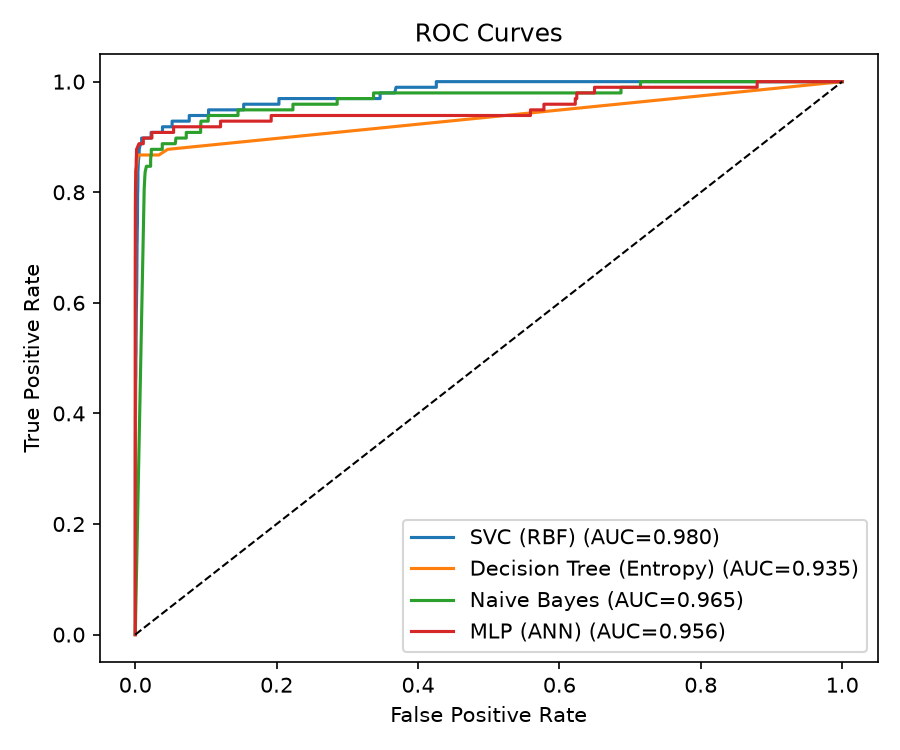

In [ ]:
from IPython.display import Image, display

# Display ROC Curves
display(Image(filename=str(FIGURES_DIR / "roc_curves.png")))

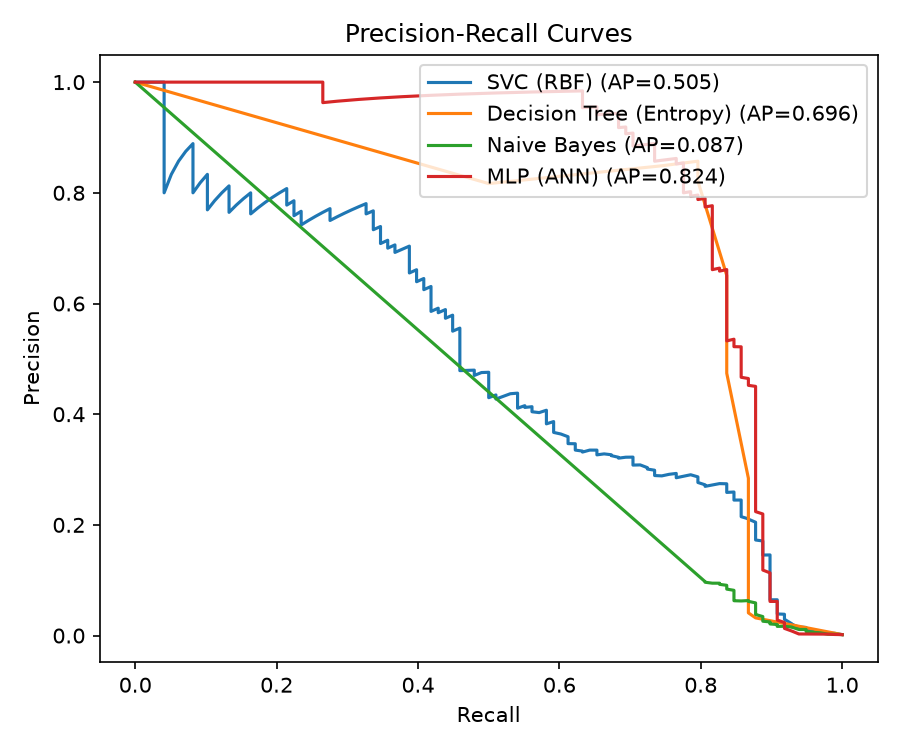

In [ ]:
# Display Precision-Recall Curves
display(Image(filename=str(FIGURES_DIR / "pr_curves.png")))

### 5.2 Confusion Matrices & Grouped Metric Comparison

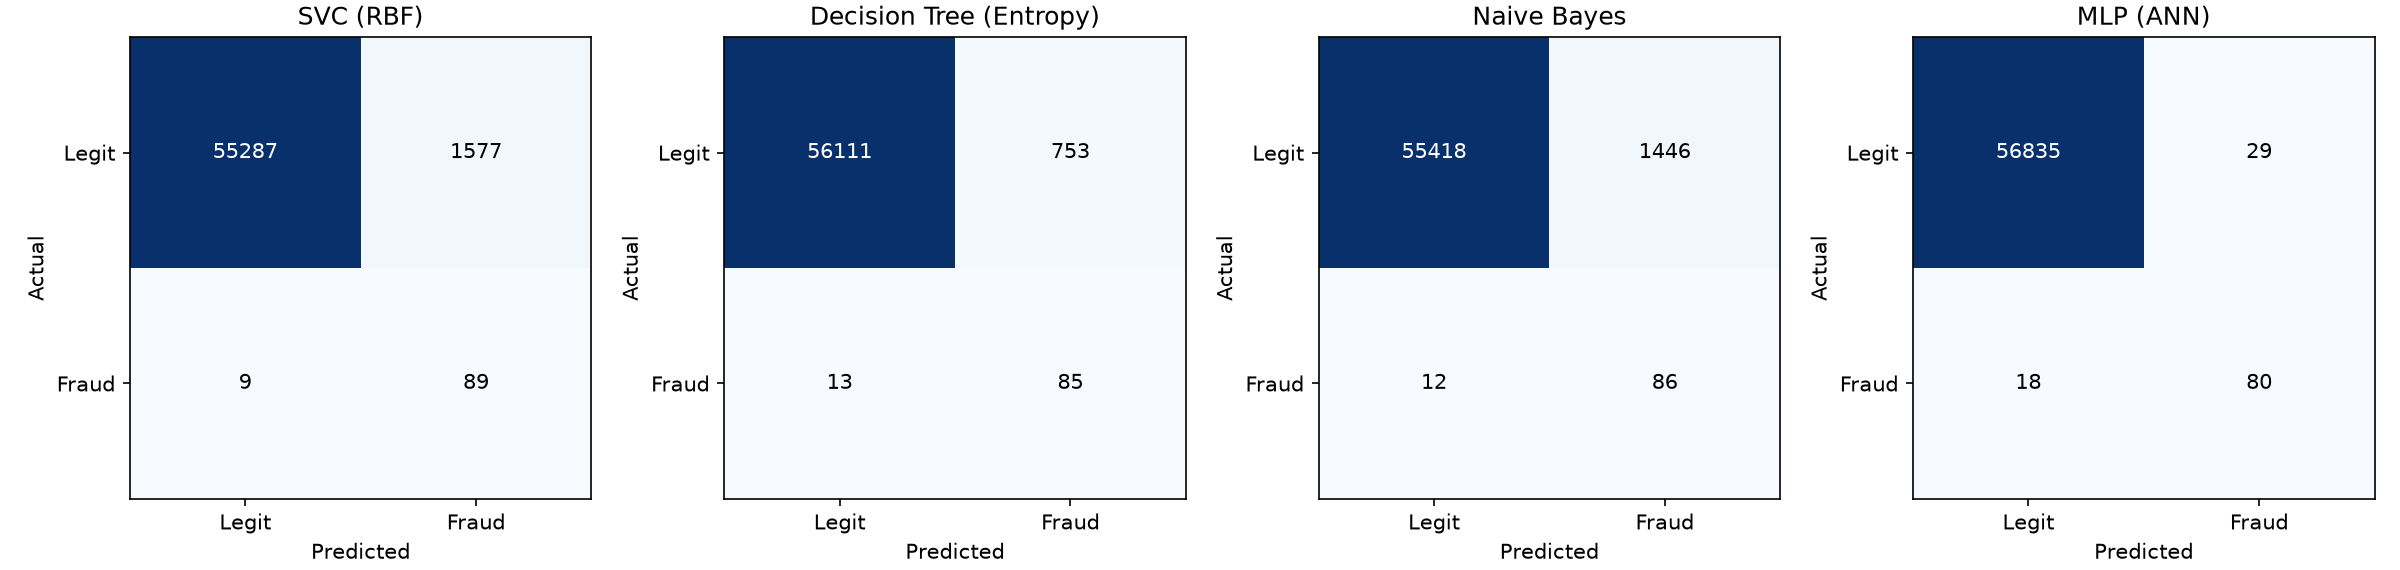

In [ ]:
display(Image(filename=str(FIGURES_DIR / "confusion_matrices.png")))

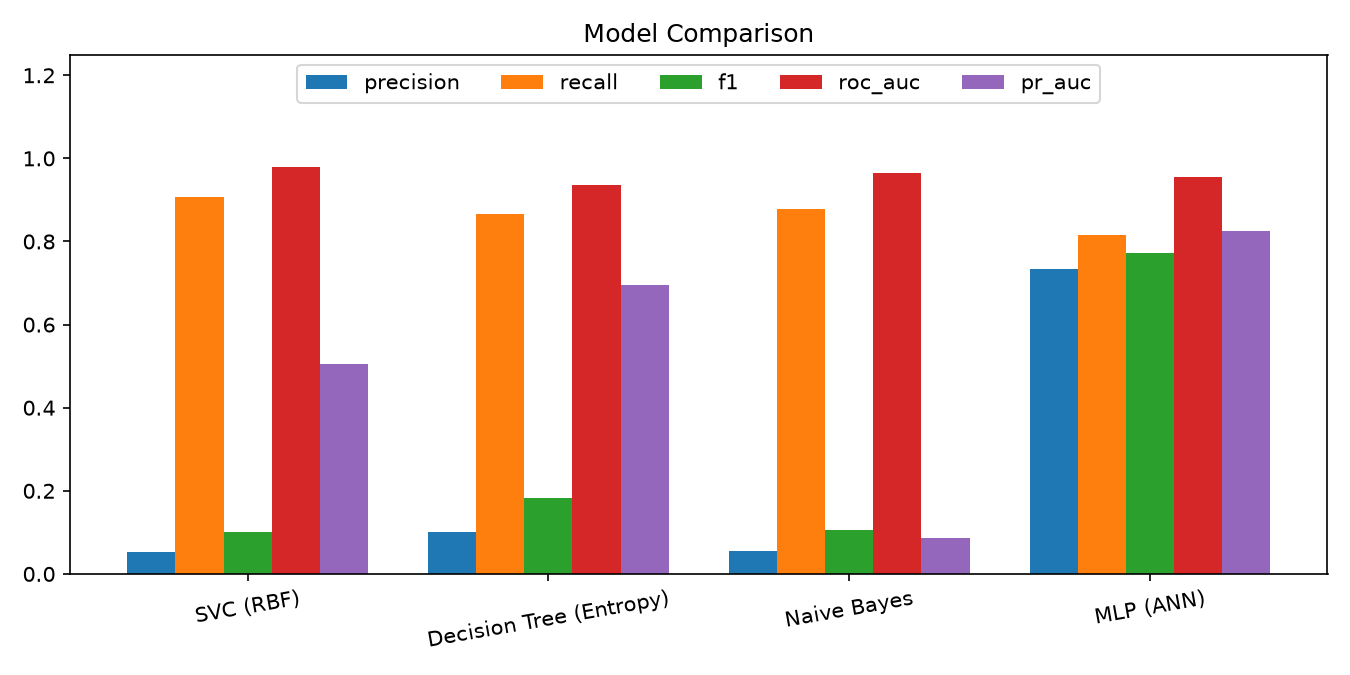

In [ ]:
display(Image(filename=str(FIGURES_DIR / "metric_comparison.png")))

### 5.3 Bias-Variance Diagnostics, Feature Importance & Depth Complexity Sweep
* **Feature Importance:** PCA component **`V14`** accounts for **`67.71%`** of total information gain in the Entropy Decision Tree, followed by **`V4` (`7.37%`)** and **`V12` (`6.72%`)**.
* **Bias-Variance Trade-off:** SVC and Naive Bayes suffer from high bias (both Train F1 and Test F1 remain near `~0.10`), whereas MLP achieves strong expressiveness (`Train F1 = 0.9153`, `Test F1 = 0.7729`) with controlled variance.

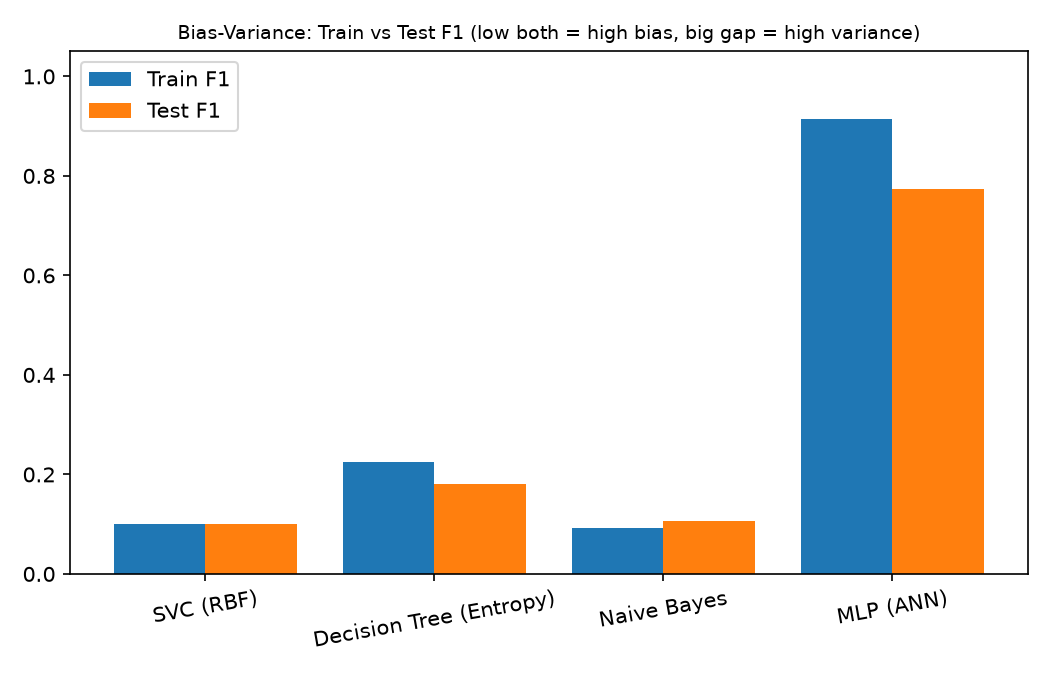

In [ ]:
display(Image(filename=str(FIGURES_DIR / "bias_variance.png")))

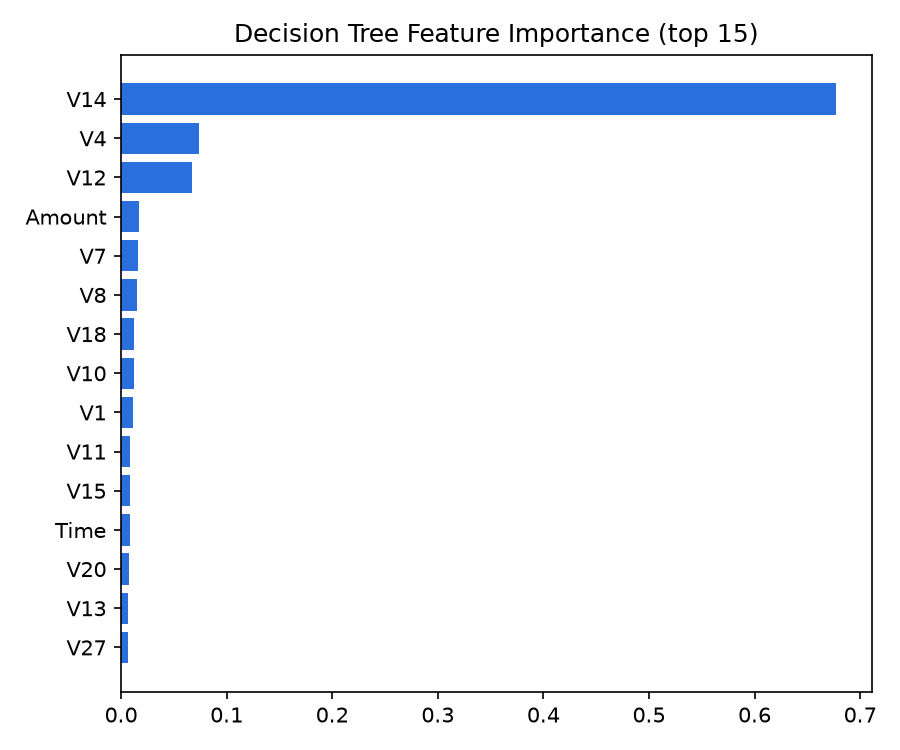

In [ ]:
display(Image(filename=str(FIGURES_DIR / "feature_importance.png")))

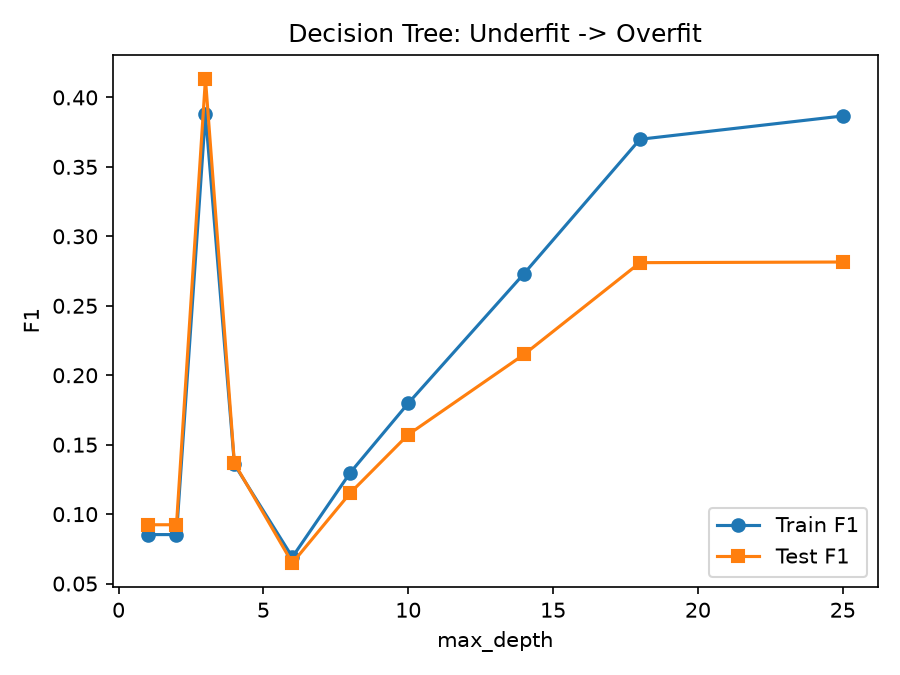

In [ ]:
display(Image(filename=str(FIGURES_DIR / "decision_tree_depth_curve.png")))

## 6. Three-Tier Risk Scoring Policy & Full-Stack Deployment Architecture
Because SMOTE shifts the training class prior from `0.1727%` to `50%`, raw `predict_proba()` outputs act as **relative risk scores** rather than calibrated posterior probabilities. In the deployed **FastAPI + SQLite + Streamlit** system (`backend/main.py` & `frontend/app.py`), every incoming transaction payload is scored and mapped into three operational actions:
* **LOW Risk (`< 30%`):** Auto-Approve payment with zero customer friction.
* **MEDIUM Risk (`30% – 70%`):** Trigger **Step-Up 6-Digit SMS OTP Verification** before settlement.
* **HIGH Risk (`>= 70%`):** Decline payment immediately and flag for fraud operations audit.

In [ ]:
def classify_risk_band(score: float) -> tuple[str, str]:
    if score < LOW_THRESHOLD:
        return "LOW", "APPROVE"
    elif score < HIGH_THRESHOLD:
        return "MEDIUM", "STEP-UP OTP VERIFICATION"
    return "HIGH", "DECLINE & FLAG"

# Simulate scoring policy across representative risk scores observed in system verification
sample_cases = [
    ("TXN-000037 (Regular Checkout €499.99)", "MLP (ANN)", 0.000),
    ("TXN-000002 (Borderline Checkout €30.31)", "MLP (ANN)", 0.474),
    ("TXN-BORDERLINE (Borderline Checkout €19.99)", "MLP (ANN)", 0.538),
    ("LOG-000033 (Held-out Fraud Sample $30.30)", "MLP (ANN)", 0.998),
    ("LOG-000001 (Held-out Fraud Sample $99.99)", "MLP (ANN)", 1.000),
]

print(f"{'Transaction Case':<44} | {'Model':<10} | {'Risk %':>7} | {'Band':<6} | {'Policy Action'}")
print("-" * 102)
for label, algo, prob in sample_cases:
    band, action = classify_risk_band(prob)
    print(f"{label:<44} | {algo:<10} | {prob*100:6.1f}% | {band:<6} | {action}")

Transaction Case                             | Model      |  Risk % | Band   | Policy Action
------------------------------------------------------------------------------------------------------
TXN-000037 (Regular Checkout €499.99)        | MLP (ANN)  |    0.0% | LOW    | APPROVE
TXN-000002 (Borderline Checkout €30.31)      | MLP (ANN)  |   47.4% | MEDIUM | STEP-UP OTP VERIFICATION
TXN-BORDERLINE (Borderline Checkout €19.99)  | MLP (ANN)  |   53.8% | MEDIUM | STEP-UP OTP VERIFICATION
LOG-000033 (Held-out Fraud Sample $30.30)    | MLP (ANN)  |   99.8% | HIGH   | DECLINE & FLAG
LOG-000001 (Held-out Fraud Sample $99.99)    | MLP (ANN)  |  100.0% | HIGH   | DECLINE & FLAG